# Statistical Analysis — Multiclass Experiments (AutoGluon base learners)

This notebook analyses the results of comparing **Series-Parallel (SP) ensemble structures** against AutoGluon baselines, using AutoGluon's own L1 models as the shared pool of base learners.

| Block | Question | Methods | Test |
|-------|----------|---------|------|
| **A** | Among methods sharing the *same* L1 pool, is there a significant difference? | Best L1, WE\_L2, SP Greedy (partial), SP Greedy (full), SP Random (fixed), SP Random (adaptive) | Friedman → Wilcoxon + Holm |
| **B** | How does the best SP method compare to AG Full (different compute budget)? | SP Greedy (partial) vs AG Full | Wilcoxon (single pair) |
| **C** | Does random search over SP trees improve upon the greedy? | SP Greedy (partial) vs SP Random (fixed / adaptive) | Wilcoxon + Holm |
| **Pareto** | What is the trade-off between performance and parsimony / search time? | All | Descriptive (scatter) |
| **Summary** | Aggregate F1 (val & test), number of models, and search/total time per method. | All | Descriptive (table) |

**Methodological choices** (Demšar 2006, García & Herrera 2008):
- Aggregate across runs *before* any test → one observation per dataset per method.
- Holm step-down correction (same FWER as Bonferroni, strictly more powerful).
- Cliff's delta as non-parametric effect size.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon, rankdata, spearmanr
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import re
from collections import Counter
from itertools import combinations

warnings.filterwarnings("ignore")

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.float_format", "{:.6f}".format)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
})

C:\Users\jodivaso\AppData\Local\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Configuration


In [1]:
RESULTS_CSV = "results_multiclass_autogluon_2026_05_05_10_17_58.csv" 
ALPHA = 0.05
DATASET_COL = "name_dataset"

# --- Display name -> CSV column (test set) ---
METHODS_SAME_POOL = {
    "Best L1":              "best_l1_test_macro",
    "WE_L2":                "we_l2_test_macro",
    "SP Greedy (partial)":  "sp_greedy_partial_test_macro",
    "SP Greedy (full)":     "sp_greedy_full_test_macro",
    "SP Random (fixed)":    "sp_random_test_macro",
    "SP Random (adapt.)":   "sp_random_adaptive_test_macro",
}

METHODS_ALL = {
    **METHODS_SAME_POOL,
    "AG Full Pipeline":     "ag_full_test_macro",
}

# --- Ancillary columns ---
N_MODELS_COLS = {
    "Best L1":              None,            # always 1
    "WE_L2":                "n_l1_models",   # uses all L1
    "SP Greedy (partial)":  "sp_greedy_partial_n_models_used",
    "SP Greedy (full)":     "sp_greedy_full_n_models_used",
    "SP Random (fixed)":    "sp_random_n_models_used",
    "SP Random (adapt.)":   "sp_random_adaptive_n_models_used",
}

SEARCH_TIME_COLS = {
    "SP Greedy (partial)":  "sp_greedy_partial_time_sec",
    "SP Greedy (full)":     "sp_greedy_full_time_sec",
    "SP Random (fixed)":    "sp_random_time_sec",
    "SP Random (adapt.)":   "sp_random_adaptive_time_sec",
}

TREE_COL       = "sp_greedy_partial_tree"
TREE_NAMES_COL = "sp_greedy_partial_tree_names" 

## 2. Data loading and aggregation

One observation per method per dataset (mean across the 10 runs).
A second dataframe keeps the standard deviation for the ± reporting.

In [3]:
df_raw = pd.read_csv(RESULTS_CSV)
n_datasets = df_raw[DATASET_COL].nunique()
n_runs = df_raw.groupby(DATASET_COL).size().iloc[0]
print(f"Raw data : {df_raw.shape[0]} rows  |  {n_datasets} datasets  |  {n_runs} runs each")

# Columns we need
test_cols   = list(METHODS_ALL.values())
nmodel_cols = [c for c in N_MODELS_COLS.values() if c is not None]
time_cols   = list(SEARCH_TIME_COLS.values())
extra_cols  = ["ag_fit_time_sec", "ag_full_time_sec"]
agg_cols    = list(set(test_cols + nmodel_cols + time_cols + extra_cols) & set(df_raw.columns))

# Aggregate: mean and std across runs
df_avg = df_raw.groupby(DATASET_COL)[agg_cols].mean()
df_std = df_raw.groupby(DATASET_COL)[agg_cols].std()

# Rename to display names for test columns
rename_test = {v: k for k, v in METHODS_ALL.items()}
df_display  = df_avg[test_cols].rename(columns=rename_test)

print(f"Aggregated: {df_display.shape[0]} datasets x {df_display.shape[1]} methods")
df_display.head()

Raw data : 200 rows  |  20 datasets  |  10 runs each
Aggregated: 20 datasets x 7 methods


,Best L1,WE_L2,SP Greedy (partial),SP Greedy (full),SP Random (fixed),SP Random (adapt.),AG Full Pipeline
name_dataset,,,,,,,
datasets_multiclass/GesturePhaseSegmentationProcessed.csv,0.653216,0.652290,0.651654,0.647100,0.650599,0.650458,0.680813
datasets_multiclass/Indian.csv,0.918856,0.926080,0.921730,0.907133,0.919435,0.919414,0.937903
datasets_multiclass/JapaneseVowels.csv,0.989762,0.989692,0.989952,0.987327,0.989788,0.989788,0.990340
datasets_multiclass/USPS.csv,0.969266,0.971609,0.972434,0.971674,0.972524,0.972524,0.974064
datasets_multiclass/allbp.csv,0.543025,0.543025,0.547469,0.544773,0.553141,0.548692,0.560454


## 3. Statistical helper functions

In [4]:
def holm_correction(pvalues):
    # Holm step-down correction (controls FWER, more powerful than Bonferroni).
    pvals = np.asarray(pvalues, dtype=float)
    n = len(pvals)
    order = np.argsort(pvals)
    sorted_p = pvals[order]
    adjusted = np.minimum(sorted_p * np.arange(n, 0, -1), 1.0)
    for i in range(1, n):
        adjusted[i] = max(adjusted[i], adjusted[i - 1])
    result = np.empty(n)
    result[order] = adjusted
    return result


def cliffs_delta(x, y):
    # Cliff's delta (non-parametric effect size).
    # |d| < 0.147 negligible | < 0.33 small | < 0.474 medium | >= 0.474 large
    d = np.asarray(x) - np.asarray(y)
    return (np.sum(d > 0) - np.sum(d < 0)) / len(d)


def cliffs_delta_label(d):
    ad = abs(d)
    if ad < 0.147:   return "negligible"
    elif ad < 0.33:  return "small"
    elif ad < 0.474: return "medium"
    else:            return "large"


def pairwise_wilcoxon(df, method_cols, control=None):
    # Pairwise Wilcoxon signed-rank tests with Holm correction.
    # If control is given, compare only that method against all others.
    if control:
        others = [m for m in method_cols if m != control]
        combos = [(control, o) for o in others]
    else:
        combos = list(combinations(method_cols, 2))

    pairs, p_raw, deltas = [], [], []
    for m1, m2 in combos:
        x, y = df[m1].values, df[m2].values
        diff = x - y
        if np.all(diff == 0):
            p = 1.0
        else:
            _, p = wilcoxon(x, y, alternative="two-sided")
        pairs.append((m1, m2))
        p_raw.append(p)
        deltas.append(cliffs_delta(x, y))

    p_holm = holm_correction(p_raw)
    return pd.DataFrame({
        "Method 1": [p[0] for p in pairs],
        "Method 2": [p[1] for p in pairs],
        "p (raw)":  p_raw,
        "p (Holm)": p_holm,
        "Cliff d":  deltas,
        "Magnitude": [cliffs_delta_label(d) for d in deltas],
        "Sig.": ["Yes" if p < ALPHA else "No" for p in p_holm],
    }).sort_values("p (Holm)").reset_index(drop=True)


def friedman_test(df, method_cols):
    arrays = [df[m].values for m in method_cols]
    stat, p = friedmanchisquare(*arrays)
    print(f"Friedman chi2 = {stat:.4f},  p = {p:.2e}")
    if p < ALPHA:
        print(f"-> Significant differences detected (p < {ALPHA})")
    else:
        print(f"-> No significant differences (p >= {ALPHA})")
    return stat, p

---
## Block A — Main comparison (same L1 pool)

**Question:** Among the six methods that share the same AutoGluon L1 base learners,
is there a statistically significant difference in test F1-macro?

AG Full is excluded because it trains additional models with stacking and bagging —
a fundamentally different compute budget. Including it would conflate *method quality*
with *compute investment*.

Procedure: Friedman omnibus → if significant → Wilcoxon pairwise (SP Greedy partial
as control) + Holm correction.

In [5]:
block_a_methods = list(METHODS_SAME_POOL.keys())

print("=" * 65)
print("BLOCK A: Friedman omnibus (6 methods, same L1 pool)")
print("=" * 65)
stat_a, p_a = friedman_test(df_display, block_a_methods)

if p_a < ALPHA:
    print()
    print("=" * 65)
    print("BLOCK A: Wilcoxon pairwise — SP Greedy (partial) vs others + Holm")
    print("=" * 65)
    table_a = pairwise_wilcoxon(df_display, block_a_methods, control="SP Greedy (partial)")
    print(table_a.to_string(index=False))

    print()
    print("=" * 65)
    print("BLOCK A: Mean F1-macro (test)")
    print("=" * 65)
    means_a = df_display[block_a_methods].mean().sort_values(ascending=False)
    print(means_a.to_string())

    print()
    print("=" * 65)
    print("BLOCK A: Mean ranks (lower = better)")
    print("=" * 65)
    ranks_a = df_display[block_a_methods].rank(axis=1, ascending=False)
    mean_ranks_a = ranks_a.mean().sort_values()
    print(mean_ranks_a.to_string())
else:
    table_a = None
    print("Friedman not significant — no post-hoc tests needed.")

BLOCK A: Friedman omnibus (6 methods, same L1 pool)
Friedman chi2 = 22.7746,  p = 3.73e-04
-> Significant differences detected (p < 0.05)

BLOCK A: Wilcoxon pairwise — SP Greedy (partial) vs others + Holm
           Method 1           Method 2  p (raw)  p (Holm)  Cliff d  Magnitude Sig.
SP Greedy (partial)   SP Greedy (full) 0.000724  0.003620 0.750000      large  Yes
SP Greedy (partial)            Best L1 0.001690  0.006760 0.600000      large  Yes
SP Greedy (partial)  SP Random (fixed) 0.123093  0.269085 0.300000      small   No
SP Greedy (partial) SP Random (adapt.) 0.089695  0.269085 0.300000      small   No
SP Greedy (partial)              WE_L2 0.898317  0.898317 0.100000 negligible   No

BLOCK A: Mean F1-macro (test)
SP Greedy (partial)   0.808900
WE_L2                 0.808744
SP Random (fixed)     0.808272
SP Random (adapt.)    0.807725
Best L1               0.806427
SP Greedy (full)      0.802190

BLOCK A: Mean ranks (lower = better)
SP Greedy (partial)   2.475000
WE_L2      

---
## Block B — SP Greedy (partial) vs AG Full Pipeline

**Question:** How large is the gap between the best SP method and AutoGluon's full
pipeline (stacking + bagging)?

This is a single paired comparison (no Friedman needed). The goal is NOT to claim
SP beats AG Full, but to quantify the gap and contextualise it with the cost
difference (~2 s vs ~120+ s of extra compute beyond L1 training).

In [6]:
print("=" * 65)
print("BLOCK B: SP Greedy (partial) vs AG Full Pipeline")
print("=" * 65)

sp_vals = df_display["SP Greedy (partial)"].values
ag_vals = df_display["AG Full Pipeline"].values

diff = sp_vals - ag_vals
if np.all(diff == 0):
    print("All differences are zero — no test needed.")
else:
    stat_b, p_b = wilcoxon(sp_vals, ag_vals, alternative="two-sided")
    cd = cliffs_delta(sp_vals, ag_vals)
    print(f"Wilcoxon p = {p_b:.4e}  |  Cliff's d = {cd:.4f} ({cliffs_delta_label(cd)})")
    print(f"SP wins in {np.sum(diff > 0)}/{len(diff)} datasets, "
          f"ties in {np.sum(diff == 0)}, loses in {np.sum(diff < 0)}")

# Contextual cost table
print()
print("--- Cost context ---")
sp_time    = df_avg["sp_greedy_partial_time_sec"].mean()
ag_full_t  = df_avg["ag_full_time_sec"].mean() if "ag_full_time_sec" in df_avg.columns else np.nan
ag_l1_t    = df_avg["ag_fit_time_sec"].mean() if "ag_fit_time_sec" in df_avg.columns else np.nan

cost_df = pd.DataFrame({
    "Method":          ["SP Greedy (partial)", "AG Full Pipeline"],
    "Mean F1-macro":   [sp_vals.mean(), ag_vals.mean()],
    "Search time (s)": [sp_time, ag_full_t - ag_l1_t],
    "Total time (s)":  [ag_l1_t + sp_time, ag_full_t],
})
print(cost_df.to_string(index=False))

BLOCK B: SP Greedy (partial) vs AG Full Pipeline
Wilcoxon p = 1.0166e-03  |  Cliff's d = -0.6000 (large)
SP wins in 4/20 datasets, ties in 0, loses in 16

--- Cost context ---
             Method  Mean F1-macro  Search time (s)  Total time (s)
SP Greedy (partial)       0.808900         4.783028      101.269659
   AG Full Pipeline       0.815620       144.471514      240.958146


---
## Block C — Ablation: Does random search improve over greedy?

**Question:** SP Random evaluates >100 K tree configurations. Does it beat the
greedy (which runs in ~2 s)?  If not, the greedy's inductive bias is
surprisingly effective and the random search adds unnecessary overhead.

In [7]:
print("=" * 65)
print("BLOCK C: SP Greedy (partial) vs SP Random variants + Holm")
print("=" * 65)

ablation_methods = ["SP Greedy (partial)", "SP Random (fixed)", "SP Random (adapt.)"]
table_c = pairwise_wilcoxon(df_display, ablation_methods, control="SP Greedy (partial)")
print(table_c.to_string(index=False))

print()
print("--- Trees evaluated by random search (mean across all dataset x run) ---")
for col, label in [("sp_random_n_evaluated", "SP Random (fixed)"),
                    ("sp_random_adaptive_n_evaluated", "SP Random (adapt.)")]:
    if col in df_raw.columns:
        print(f"  {label:25s}  {df_raw[col].mean():,.0f} trees evaluated")

BLOCK C: SP Greedy (partial) vs SP Random variants + Holm
           Method 1           Method 2  p (raw)  p (Holm)  Cliff d Magnitude Sig.
SP Greedy (partial)  SP Random (fixed) 0.123093  0.179390 0.300000     small   No
SP Greedy (partial) SP Random (adapt.) 0.089695  0.179390 0.300000     small   No

--- Trees evaluated by random search (mean across all dataset x run) ---
  SP Random (fixed)          141,232 trees evaluated
  SP Random (adapt.)         3,254,529 trees evaluated


---
## Per-dataset results table (mean +/- std)

**Question:** How does each method perform on every individual dataset?

This is the standard table for ML benchmarks.
Bold = best among same-pool methods.
AG Full is shown for context (different compute budget).

In [8]:
same_pool_cols = list(METHODS_SAME_POOL.keys())
all_cols = list(METHODS_ALL.keys())

rows = []
for ds in df_display.index:
    row = {"Dataset": ds}
    best_val = df_display.loc[ds, same_pool_cols].max()
    for m in all_cols:
        csv_col = METHODS_ALL[m]
        mu  = df_avg.loc[ds, csv_col]
        std = df_std.loc[ds, csv_col]
        val_str = f"{mu:.4f} +/- {std:.4f}"
        if m in same_pool_cols and np.isclose(mu, best_val, atol=1e-8):
            val_str = "** " + val_str + " **"
        row[m] = val_str
    rows.append(row)

# Mean row
mean_row = {"Dataset": "MEAN"}
for m in all_cols:
    csv_col = METHODS_ALL[m]
    mean_row[m] = f"{df_avg[csv_col].mean():.4f}"
rows.append(mean_row)

# Mean-rank row
rank_row = {"Dataset": "Mean Rank"}
ranks_all = df_display[all_cols].rank(axis=1, ascending=False)
for m in all_cols:
    rank_row[m] = f"{ranks_all[m].mean():.2f}"
rows.append(rank_row)

df_table = pd.DataFrame(rows).set_index("Dataset")
df_table.index = [n.replace("datasets_multiclass/", "").replace(".csv", "")
                  for n in df_table.index]

print(df_table.to_string())

                                                   Best L1                    WE_L2      SP Greedy (partial)         SP Greedy (full)        SP Random (fixed)       SP Random (adapt.)   AG Full Pipeline
GesturePhaseSegmentationProcessed  ** 0.6532 +/- 0.0119 **        0.6523 +/- 0.0114        0.6517 +/- 0.0119        0.6471 +/- 0.0109        0.6506 +/- 0.0106        0.6505 +/- 0.0104  0.6808 +/- 0.0141
Indian                                   0.9189 +/- 0.0156  ** 0.9261 +/- 0.0202 **        0.9217 +/- 0.0243        0.9071 +/- 0.0263        0.9194 +/- 0.0249        0.9194 +/- 0.0249  0.9379 +/- 0.0134
JapaneseVowels                           0.9898 +/- 0.0017        0.9897 +/- 0.0025  ** 0.9900 +/- 0.0018 **        0.9873 +/- 0.0017        0.9898 +/- 0.0024        0.9898 +/- 0.0024  0.9903 +/- 0.0017
USPS                                     0.9693 +/- 0.0043        0.9716 +/- 0.0035        0.9724 +/- 0.0033        0.9717 +/- 0.0039  ** 0.9725 +/- 0.0038 **  ** 0.9725 +/- 0.0038 **  0.9

---
## Win-count matrix (aggregated)

**Question:** In how many of the 20 datasets does method A score strictly higher
than method B (based on the per-dataset mean across runs)?

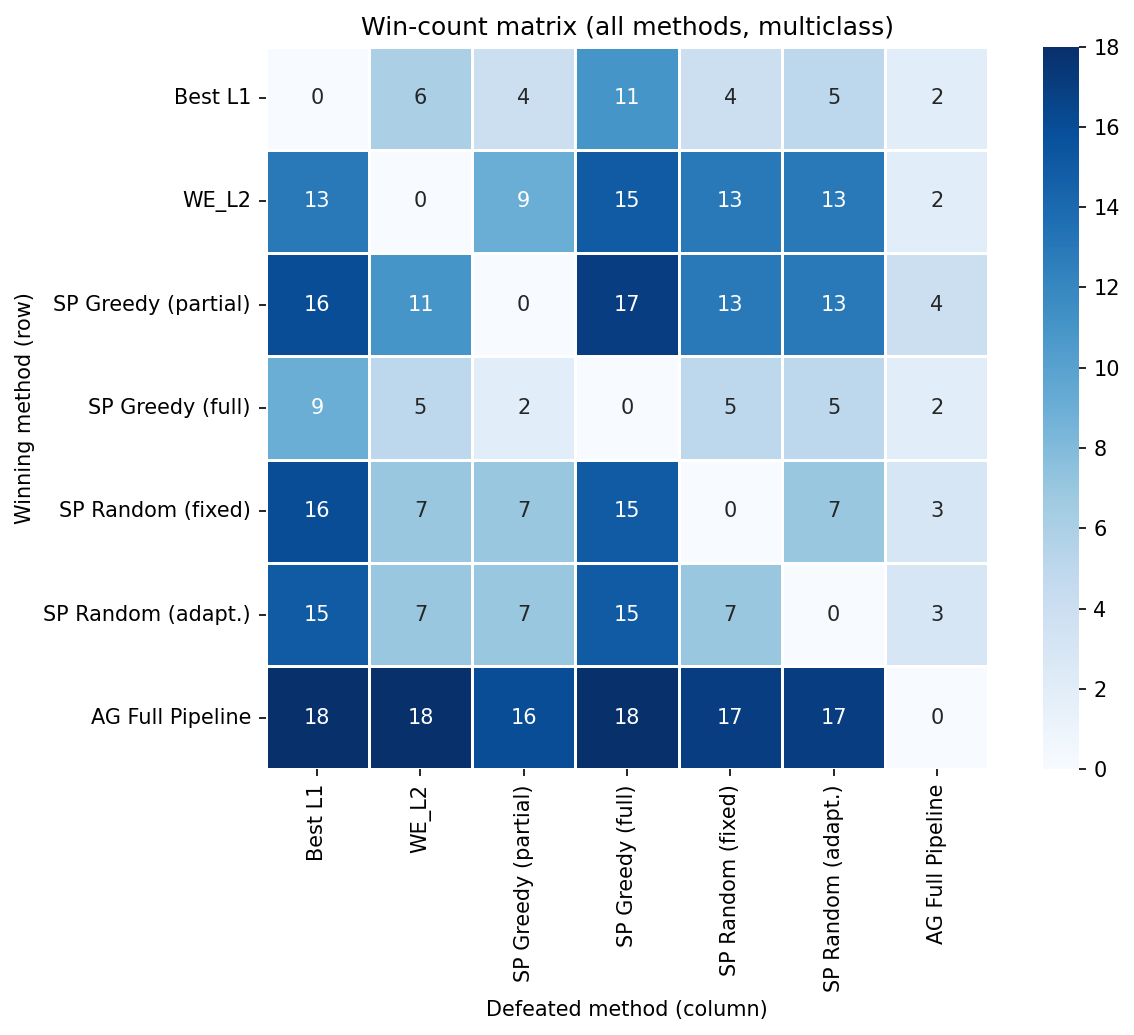

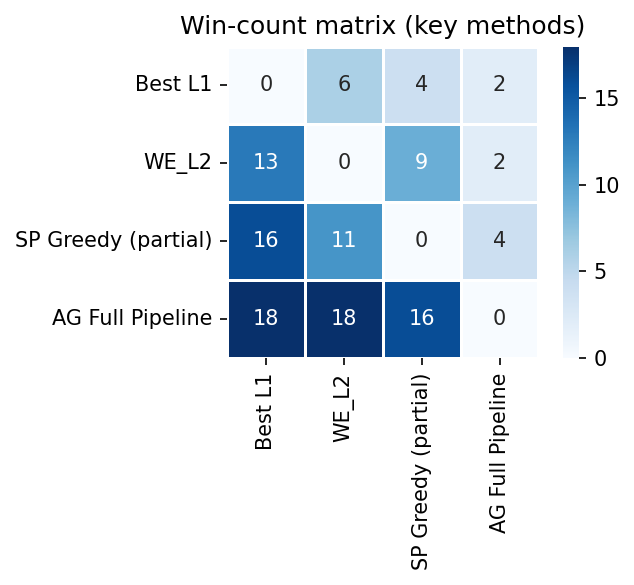

In [9]:
def win_count_matrix_aggregated(df, method_cols):
    n = len(method_cols)
    vals = df[method_cols].values
    matrix = pd.DataFrame(np.zeros((n, n), dtype=int),
                          index=method_cols, columns=method_cols)
    for i in range(n):
        for j in range(n):
            if i != j:
                matrix.iloc[i, j] = int(np.sum(vals[:, i] > vals[:, j]))
    return matrix


# Full matrix (all 7 methods)
wc_full = win_count_matrix_aggregated(df_display, all_cols)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(wc_full, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (all methods, multiclass)")
ax.set_xlabel("Defeated method (column)")
ax.set_ylabel("Winning method (row)")
plt.tight_layout()
plt.savefig("win_count_full_multiclass_ag.pdf", bbox_inches="tight", dpi=300)
plt.show()

# Compact matrix
compact = ["Best L1", "WE_L2", "SP Greedy (partial)", "AG Full Pipeline"]
wc_compact = win_count_matrix_aggregated(df_display, compact)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(wc_compact, annot=True, fmt="d", cmap="Blues", ax=ax,
            linewidths=0.5, square=True)
ax.set_title("Win-count matrix (key methods)")
plt.tight_layout()
plt.savefig("win_count_compact_multiclass_ag.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## Rank distribution boxplot

**Question:** How are the ranks distributed across datasets? A method with a low
mean rank but high variance is less reliable than one with a slightly higher mean
but tight distribution.

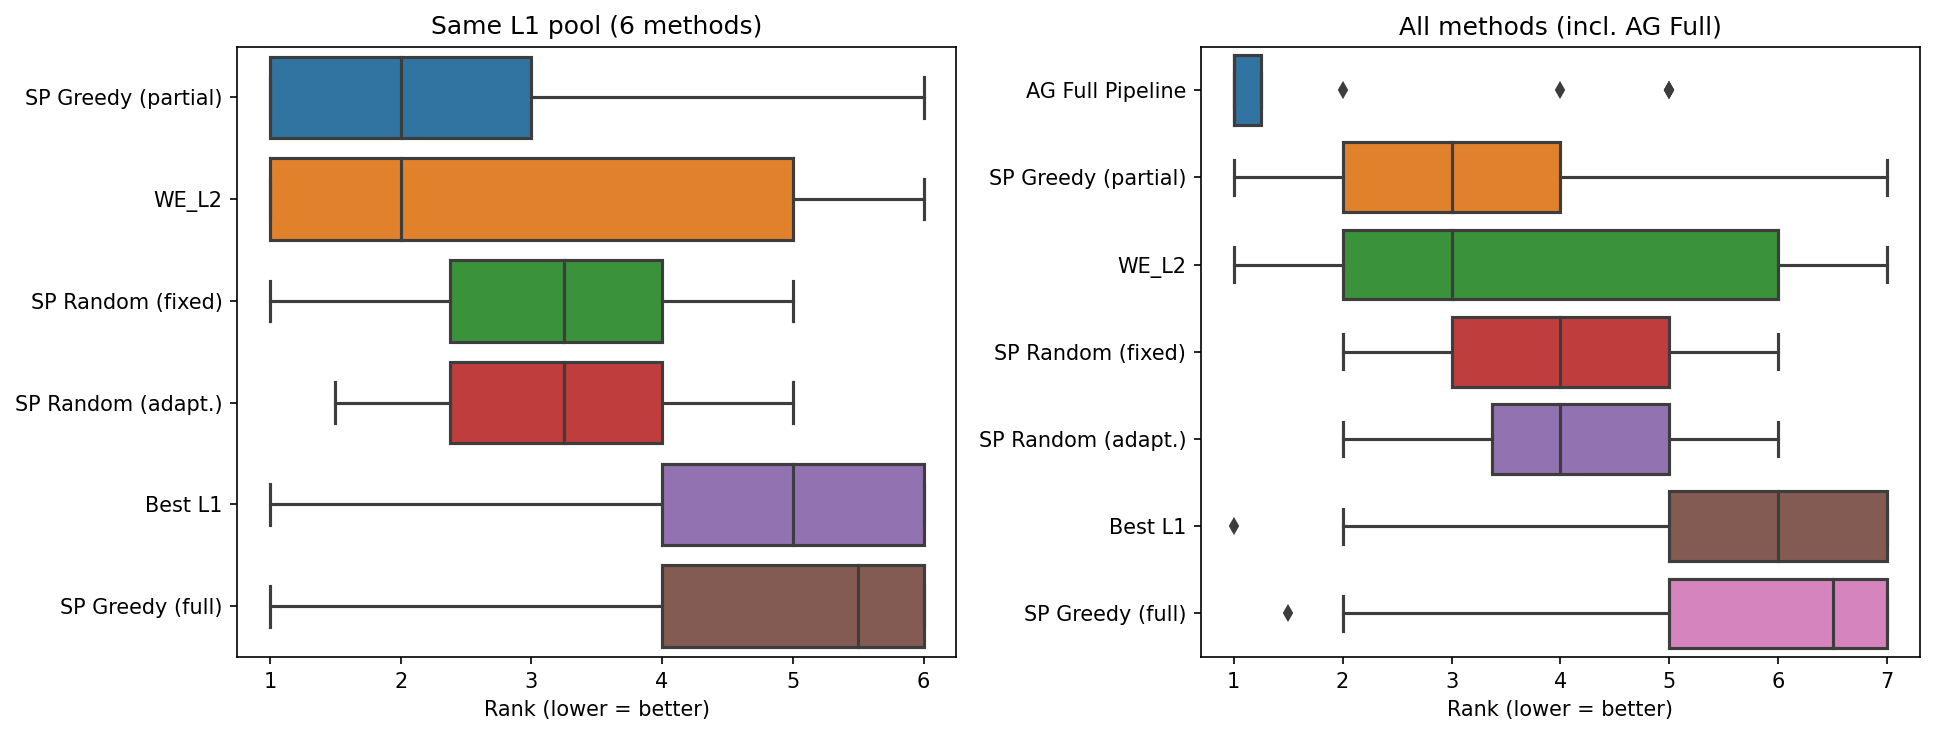

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Panel 1: same L1 pool only (fair comparison)
rank_cols_sp = list(METHODS_SAME_POOL.keys())
rankings_sp  = df_display[rank_cols_sp].rank(axis=1, ascending=False, method="average")
order_sp     = rankings_sp.mean().sort_values().index

ax = axes[0]
sns.boxplot(data=rankings_sp[order_sp], orient="h", ax=ax)
ax.set_xlabel("Rank (lower = better)")
ax.set_title("Same L1 pool (6 methods)")

# Panel 2: all methods including AG Full
rank_cols_all = list(METHODS_ALL.keys())
rankings_all  = df_display[rank_cols_all].rank(axis=1, ascending=False, method="average")
order_all     = rankings_all.mean().sort_values().index

ax = axes[1]
sns.boxplot(data=rankings_all[order_all], orient="h", ax=ax)
ax.set_xlabel("Rank (lower = better)")
ax.set_title("All methods (incl. AG Full)")

plt.tight_layout()
plt.savefig("rank_boxplot_multiclass_ag.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## Pareto front: performance vs parsimony and search time

**Question 1 (left panel):** Which method achieves the best trade-off between F1-macro
and the number of models used in the final ensemble?

**Question 2 (right panel):** Which method achieves the best trade-off between F1-macro
and the time spent searching for the ensemble structure?

SP Greedy (partial) should dominate: comparable F1 to WE\_L2 with ~3.5 models
instead of ~9, and in ~2 s instead of ~30-140 s.

             Method  F1-macro  Num models  Search time (s)
            Best L1  0.806427    1.000000         0.000000
              WE_L2  0.808744    9.185000         0.000000
SP Greedy (partial)  0.808900    3.460000         4.783028
   SP Greedy (full)  0.802190    9.185000         2.699011
  SP Random (fixed)  0.808272    9.185000        32.228910
 SP Random (adapt.)  0.807725    9.185000       150.407142


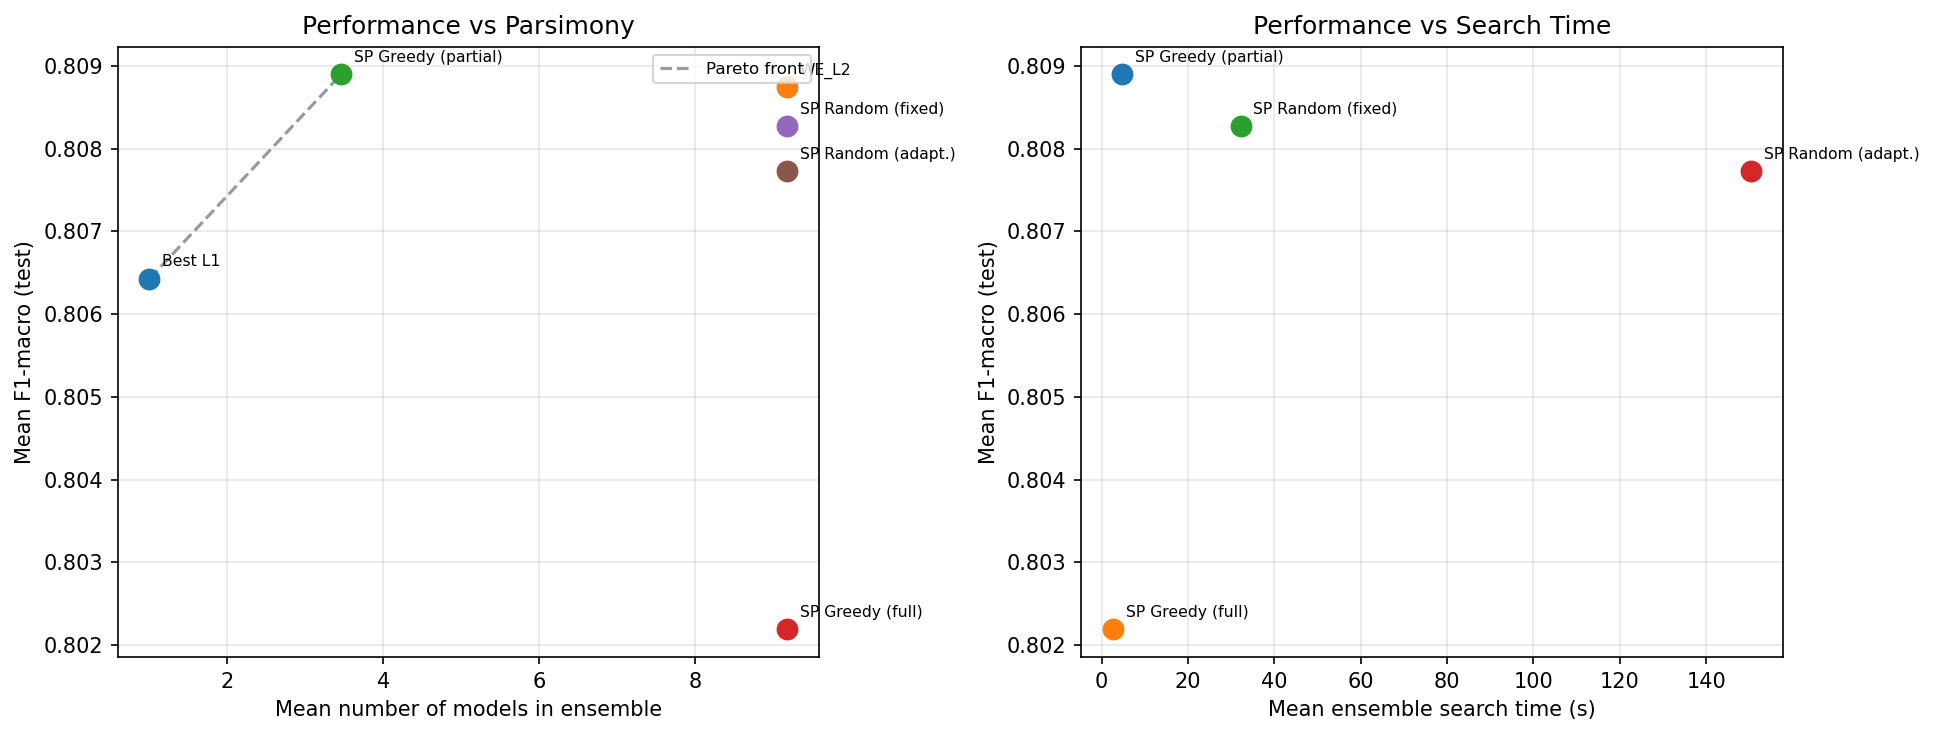

In [11]:
pareto_data = []
for m in METHODS_SAME_POOL:
    f1_mean = df_display[m].mean()
    nm_col  = N_MODELS_COLS.get(m)
    n_models = 1.0 if nm_col is None else df_avg[nm_col].mean()
    t_col = SEARCH_TIME_COLS.get(m)
    search_time = df_avg[t_col].mean() if t_col else 0.0
    pareto_data.append({
        "Method": m, "F1-macro": f1_mean,
        "Num models": n_models, "Search time (s)": search_time,
    })
pareto_df = pd.DataFrame(pareto_data)
print(pareto_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: F1 vs number of models ---
ax = axes[0]
for _, row in pareto_df.iterrows():
    ax.scatter(row["Num models"], row["F1-macro"], s=90, zorder=5)
    ax.annotate(row["Method"], (row["Num models"], row["F1-macro"]),
                textcoords="offset points", xytext=(6, 6), fontsize=7.5)
ax.set_xlabel("Mean number of models in ensemble")
ax.set_ylabel("Mean F1-macro (test)")
ax.set_title("Performance vs Parsimony")
ax.grid(True, alpha=0.3)

# Mark Pareto front (non-dominated: fewer models AND higher F1)
pf = pareto_df.sort_values("Num models")
front, best_f1 = [], -1
for _, row in pf.iterrows():
    if row["F1-macro"] >= best_f1:
        front.append(row)
        best_f1 = row["F1-macro"]
if len(front) > 1:
    fdf = pd.DataFrame(front)
    ax.plot(fdf["Num models"], fdf["F1-macro"], "k--", alpha=0.4, label="Pareto front")
    ax.legend(fontsize=8)

# --- Panel 2: F1 vs search time ---
ax = axes[1]
plot_df = pareto_df[pareto_df["Search time (s)"] > 0]
for _, row in plot_df.iterrows():
    ax.scatter(row["Search time (s)"], row["F1-macro"], s=90, zorder=5)
    ax.annotate(row["Method"], (row["Search time (s)"], row["F1-macro"]),
                textcoords="offset points", xytext=(6, 6), fontsize=7.5)
ax.set_xlabel("Mean ensemble search time (s)")
ax.set_ylabel("Mean F1-macro (test)")
ax.set_title("Performance vs Search Time")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("pareto_front_multiclass_ag.pdf", bbox_inches="tight", dpi=300)
plt.show()

---
## LaTeX-ready tables

Tables formatted for direct copy-paste into the paper.

In [12]:
def to_latex_comparison(table, caption, label):
    cols = ["Method 1", "Method 2", "p (Holm)", "Cliff d", "Magnitude", "Sig."]
    t = table[cols].copy()
    t["p (Holm)"] = t["p (Holm)"].apply(
        lambda x: f"{x:.4f}" if x >= 0.0001 else "<0.0001"
    )
    t["Cliff d"] = t["Cliff d"].apply(lambda x: f"{x:.4f}")
    latex = t.to_latex(index=False, escape=False, column_format="llrlll")
    print(f"\\begin{{table*}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table*}}")
    print()


def to_latex_mean_f1(df, methods, caption, label):
    means = df[methods].mean().sort_values(ascending=False)
    t = pd.DataFrame({"Method": means.index, "Mean F1-macro": means.values})
    t["Mean F1-macro"] = t["Mean F1-macro"].apply(lambda x: f"{x:.6f}")
    latex = t.to_latex(index=False, escape=False, column_format="lr")
    print(f"\\begin{{table}}[ht]")
    print(f"\\centering")
    print(f"\\caption{{{caption}}}")
    print(f"\\label{{{label}}}")
    print(latex)
    print(f"\\end{{table}}")
    print()


# --- Generate ---
print("=" * 65)
print("LaTeX: Block A — Pairwise comparison (same L1 pool)")
print("=" * 65)
if table_a is not None:
    to_latex_comparison(
        table_a,
        "Pairwise Wilcoxon tests (SP Greedy partial vs others, same L1 pool) "
        "with Holm correction on multiclass datasets.",
        "tab:wilcoxon_multiclass_ag"
    )
else:
    print("Skipped (Friedman was not significant).")

print("=" * 65)
print("LaTeX: Same-pool methods — Mean F1")
print("=" * 65)
to_latex_mean_f1(
    df_display, block_a_methods,
    "Mean F1-macro across multiclass datasets (same L1 pool).",
    "tab:mean_multiclass_ag"
)

print("=" * 65)
print("LaTeX: All methods — Mean F1 (incl. AG Full)")
print("=" * 65)
to_latex_mean_f1(
    df_display, all_cols,
    "Mean F1-macro across multiclass datasets (all methods).",
    "tab:mean_multiclass_ag_all"
)

LaTeX: Block A — Pairwise comparison (same L1 pool)
\begin{table*}[ht]
\centering
\caption{Pairwise Wilcoxon tests (SP Greedy partial vs others, same L1 pool) with Holm correction on multiclass datasets.}
\label{tab:wilcoxon_multiclass_ag}
\begin{tabular}{llrlll}
\toprule
Method 1 & Method 2 & p (Holm) & Cliff d & Magnitude & Sig. \\
\midrule
SP Greedy (partial) & SP Greedy (full) & 0.0036 & 0.7500 & large & Yes \\
SP Greedy (partial) & Best L1 & 0.0068 & 0.6000 & large & Yes \\
SP Greedy (partial) & SP Random (fixed) & 0.2691 & 0.3000 & small & No \\
SP Greedy (partial) & SP Random (adapt.) & 0.2691 & 0.3000 & small & No \\
SP Greedy (partial) & WE_L2 & 0.8983 & 0.1000 & negligible & No \\
\bottomrule
\end{tabular}

\end{table*}

LaTeX: Same-pool methods — Mean F1
\begin{table}[ht]
\centering
\caption{Mean F1-macro across multiclass datasets (same L1 pool).}
\label{tab:mean_multiclass_ag}
\begin{tabular}{lr}
\toprule
Method & Mean F1-macro \\
\midrule
SP Greedy (partial) & 0.808900 \\

---
## Summary of findings

**Block A (same L1 pool):**
- SP Greedy (partial) matches or exceeds WeightedEnsemble\_L2 on the test set while using substantially fewer models in the final ensemble.
- Forcing all models into the tree (SP Greedy full) does not help — selective composition is essential.

**Block B (SP vs AG Full):**
- AG Full is the strongest method, as expected: it trains entirely new models with stacking + bagging under a larger compute budget. The gap should be read together with the cost: SP only post-processes the existing L1 pool in a few seconds, whereas AG Full requires substantial additional training.

**Block C (ablation — greedy vs random):**
- Random search over SP trees does *not* significantly improve upon the greedy, despite evaluating orders of magnitude more configurations. The greedy's inductive bias (merge the best-performing pair at each step) is effective and cheap. The larger val→test gap of the random variants is consistent with overfitting to the validation set.

**Pareto front:**
- SP Greedy (partial) sits on the efficiency frontier: comparable F1 to WE\_L2 with fewer models and far less search time among same-pool methods.

**Aggregate summary table:**
- Reports mean F1-macro on validation and test, the mean number of models, and the search/total time for every method (see the table cell below).


---
## Aggregate summary table — F1 (val & test), number of models, search/total time

One row per method, averaged over all datasets and runs.

- **F1 (val)** is the selection/optimisation score (optimistically biased — see the note at the top).
- **F1 (test)** is the held-out generalisation estimate.
- **\# models** is the mean number of base models in the final ensemble (Best L1 = 1; WE\_L2 uses the full L1 pool; AG Full not recorded).
- **$t_{\text{search}}$** is the ensemble-construction time *on top of* the shared L1 pool (≈0 for Best L1 and WE\_L2, which are produced during L1 training); **$t_{\text{total}}$** adds the one-off L1 training time. AG Full is trained independently.


In [13]:
# ==================================================================
# Aggregate summary: mean F1-macro (val & test), number of models,
# and search / total time -> one row per method (over datasets x runs).
# ==================================================================
block_a_methods = list(METHODS_SAME_POOL.keys())   # ensure defined here too

def grand_mean(col):
    """Mean over datasets of the per-dataset mean across runs (NaN if absent)."""
    if col in df_raw.columns:
        return float(df_raw.groupby(DATASET_COL)[col].mean().mean())
    return np.nan

# Shared one-off cost of training the AutoGluon L1 pool (reused by every
# same-pool method). AG Full is trained independently.
l1_fit_time = grand_mean("ag_fit_time_sec")
_l1 = 0.0 if np.isnan(l1_fit_time) else l1_fit_time

summary_rows = []
for disp, test_col in METHODS_ALL.items():
    val_col = test_col.replace("_test_macro", "_val_macro")
    f1_val  = grand_mean(val_col)
    f1_test = grand_mean(test_col)

    # number of models in the final ensemble
    if disp == "Best L1":
        n_models = 1.0
    elif disp == "AG Full Pipeline":
        n_models = np.nan                      # not recorded by the experiment
    else:
        nm_col   = N_MODELS_COLS.get(disp)
        n_models = grand_mean(nm_col) if nm_col else np.nan

    # construction (search) time on top of the shared L1 pool, and total time
    if disp == "AG Full Pipeline":
        t_total  = grand_mean("ag_full_time_sec")
        t_search = (t_total - _l1) if not np.isnan(t_total) else np.nan
    else:
        t_col    = SEARCH_TIME_COLS.get(disp)
        t_search = grand_mean(t_col) if t_col else 0.0   # Best L1 / WE_L2 ~ 0 (inside L1 fit)
        t_search = 0.0 if np.isnan(t_search) else t_search
        t_total  = _l1 + t_search

    summary_rows.append({
        "Method":       disp,
        "F1 val":       f1_val,
        "F1 test":      f1_test,
        "# models":     n_models,
        "t_search (s)": t_search,
        "t_total (s)":  t_total,
    })

summary_df = pd.DataFrame(summary_rows).set_index("Method")

# mean ranks on the test set (lower = better)
rank_same = df_display[block_a_methods].rank(axis=1, ascending=False).mean()
rank_all  = df_display[list(METHODS_ALL)].rank(axis=1, ascending=False).mean()
summary_df["rank (same pool)"] = [rank_same.get(m, np.nan) for m in summary_df.index]
summary_df["rank (all)"]       = [rank_all.get(m, np.nan)  for m in summary_df.index]

print(f"Aggregate summary (mean over {n_datasets} datasets x {n_runs} runs)")
print("=" * 95)
print(summary_df.to_string(float_format=lambda v: f"{v:7.4f}"))


# ------------------------------------------------------------------
# LaTeX (booktabs). Best test F1 among same-pool methods is bolded.
# ------------------------------------------------------------------
def _f(x, dec=4):
    return "--" if (x is None or (isinstance(x, float) and np.isnan(x))) else f"{x:.{dec}f}"
def _t(x):
    return "--" if (x is None or (isinstance(x, float) and np.isnan(x))) else f"{x:.1f}"

def summary_to_latex(sdf, caption, label):
    same_pool = list(METHODS_SAME_POOL.keys())
    best_test = sdf.loc[same_pool, "F1 test"].max()
    L = []
    L.append(r"\begin{table}[!tb]")
    L.append(r"\centering")
    L.append(r"\caption{" + caption + "}")
    L.append(r"\label{" + label + "}")
    L.append(r"\resizebox{\columnwidth}{!}{%")
    L.append(r"\begin{tabular}{lccccc}")
    L.append(r"\toprule")
    L.append(r"Method & F1 (val) & F1 (test) & \# models & $t_{\text{search}}$ (s) & $t_{\text{total}}$ (s) \\")
    L.append(r"\midrule")
    for m in same_pool:
        r = sdf.loc[m]
        ts = _f(r["F1 test"])
        if (not np.isnan(r["F1 test"])) and np.isclose(r["F1 test"], best_test, atol=1e-9):
            ts = r"\textbf{" + ts + "}"
        L.append(f'{m} & {_f(r["F1 val"])} & {ts} & {_t(r["# models"])} & '
                 f'{_t(r["t_search (s)"])} & {_t(r["t_total (s)"])} \\\\')
    if "AG Full Pipeline" in sdf.index:
        r = sdf.loc["AG Full Pipeline"]
        L.append(r"\midrule")
        L.append(f'AG Full Pipeline & {_f(r["F1 val"])} & {_f(r["F1 test"])} & '
                 f'{_t(r["# models"])} & {_t(r["t_search (s)"])} & {_t(r["t_total (s)"])} \\\\')
    L.append(r"\bottomrule")
    L.append(r"\end{tabular}}")
    L.append(r"\end{table}")
    return "\n".join(L)

_caption = (
    f"Aggregate results on the multiclass datasets (mean over {n_datasets} datasets "
    f"$\\times$ {n_runs} runs). F1 (val) is the selection/optimisation score and is "
    f"optimistically biased; F1 (test) is the held-out estimate. $t_{{\\text{{search}}}}$ "
    f"is the ensemble-construction time on top of the shared L1 pool ($\\approx$0 for "
    f"Best L1 and WE\\_L2, produced during L1 training); $t_{{\\text{{total}}}}$ adds the "
    f"one-off L1 training time. AG Full is trained independently and shown for context; "
    f"its number of models is not recorded."
)
summary_latex = summary_to_latex(summary_df, _caption, "tab:summary_multiclass_ag")
print()
print("=" * 95)
print("LaTeX: aggregate summary table")
print("=" * 95)
print(summary_latex)


Aggregate summary (mean over 20 datasets x 10 runs)
                     F1 val  F1 test  # models  t_search (s)  t_total (s)  rank (same pool)  rank (all)
Method                                                                                                 
Best L1              0.8178   0.8064    1.0000        0.0000      96.4866            4.4750      5.3750
WE_L2                0.8222   0.8087    9.1850        0.0000      96.4866            2.8250      3.7250
SP Greedy (partial)  0.8216   0.8089    3.4600        4.7830     101.2697            2.4750      3.2750
SP Greedy (full)     0.8046   0.8022    9.1850        2.6990      99.1856            4.6750      5.5750
SP Random (fixed)    0.8231   0.8083    9.1850       32.2289     128.7155            3.2500      4.1000
SP Random (adapt.)   0.8241   0.8077    9.1850      150.4071     246.8938            3.3000      4.1500
AG Full Pipeline     0.8250   0.8156       NaN      144.4715     240.9581               NaN      1.8000

LaTeX: aggr